# 87 us Parrinello vacuum dataset

https://claude.ai/chat/f5fdb53d-6723-4e3f-ab89-2dffa000bfe7

https://doi.org/10.5281/zenodo.7323535

```bash
BASE="https://zenodo.org/records/7323535/files"
wget -c "$BASE/traj_comp.xtc?download=1"   -O traj_comp.xtc     # 152.8 MB
wget -c "$BASE/input.ala2.pdb?download=1"  -O input.ala2.pdb    # topology
```

1. Ray, Dhiman, Narjes Ansari, Valerio Rizzi, Michele Invernizzi, and Michele Parrinello. "Rare event kinetics from adaptive bias enhanced sampling." Journal of Chemical Theory and Computation (2022). https://doi.org/10.1021/acs.jctc.2c00806 

## 1. Extract features/dihedrals

dihedrals and features already present in data/vacuum-parrinello


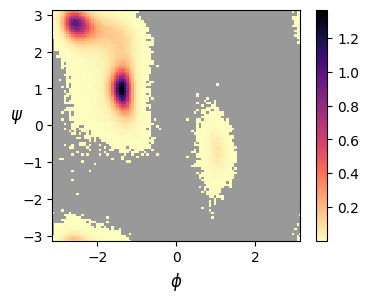

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from openmm import unit

from src.param import param_unbiased_vaccuum_parrinello
from src.data import simulation_data
from src.plots import plot_dihedrals_hist2d

p = param_unbiased_vaccuum_parrinello()
sd = simulation_data(p, lagframes=1)

sd.save_feature_data(periodic=False, recalculate=False, pdbfile=p.pdb_file)

check_simparam = False
if check_simparam:
    !gmx check -f data/vacuum-parrinello/traj.xtc

check_pbcs = False
if check_pbcs:
    from src.check_pbc import check_periodic_wrapping, reference_from_pdb

    ref = reference_from_pdb(p.pdb_file)
    print("reference pair distances:", ref.shape, ref.min().round(4), ref.max().round(4))
    print()
    result = check_periodic_wrapping(sd.features, reference=ref)

compute_pdf = False
if compute_pdf:
    from src.pdf import dihedrals_pdf

    pdf = dihedrals_pdf(sd.dihedrals)
    sd.save_and_assign_objects({"dihedrals_pdf": pdf})

fig, ax = plt.subplots(1, 1, figsize=(4, 3))
plot_dihedrals_hist2d(fig, ax, sd.dihedrals_pdf)

## 2. Train SRV

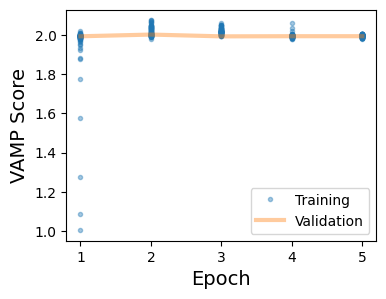

In [2]:
from tqdm.notebook import tqdm
from src.dataset import TrajectoryDataset, data_loaders
from src.vampnet import vampnet


def plot_training(sd, pngfile="notes/figures/vampnet-vacuum.png"):
    fig, ax = plt.subplots(1, 1, figsize=(4, 3))
    ax.plot(*sd.vampnet.train_scores.T, ".", alpha=0.4, label="Training")
    ax.plot(*sd.vampnet.test_scores.T, "-", linewidth=3, alpha=0.4, label="Validation")
    ax.set_xlabel("Epoch", fontsize=14)
    ax.set_ylabel("VAMP Score", fontsize=14)
    ax.legend()
    if pngfile is not None:
        fig.savefig(pngfile, bbox_inches="tight")


dataset = TrajectoryDataset(sd.features, sd.lagframes)
num_epochs = 5

train = False
if train:
    vn = vampnet(p, weighted=False)
    vn.fit(
        *data_loaders(dataset, p.frac_test, num_workers=0, prefetch_factor=4),
        num_epochs=num_epochs,
    )
    sd.save_and_assign_objects({"vampnet": vn})

plot_training(sd, pngfile=None)

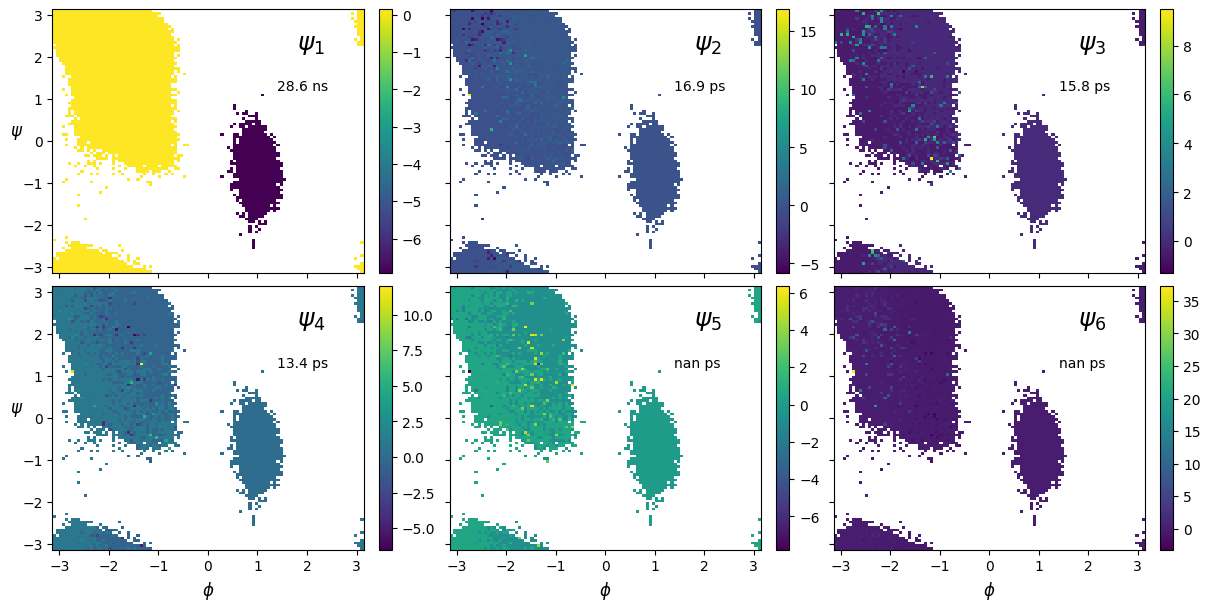

In [3]:
from src.vampnet import SRV
from src.plots import plot_eigfuncs

fit_srv = False
if fit_srv:
    srv = SRV(sd.vampnet.net, sd.lagtime).fit(dataset)
    sd.save_eigen_data(srv, num_cvs=p.num_cvs)
    sd.save_grid_data(srv, num_points=100)

fig, axs = plt.subplots(
    2, 3, figsize=(12, 6), sharex=True, sharey=True, constrained_layout=True
)
plot_eigfuncs(fig, axs, sd.theta_grid, sd.psi_grid, sd.timescales)

In [4]:
from src.eigen_noise import eigval_noise_report

eigval_noise_report(sd, dataset)

SRV eigenvalue noise report
  frame pairs N = 875,246   lag tau = 100 ps   sigma = 1/sqrt(N) = 0.00107
  modes 1-1 assumed real; null block = 5 mode(s)

  mode      lambda  lambda/sigma      t (ps)   verdict
     1    0.996511        932.28     28614.3   resolved
     2    0.002689          2.52        16.9   noise
     3    0.001790          1.67        15.8   noise
     4    0.000572          0.53        13.4   noise
     5   -0.001282         -1.20         nan   noise (lambda <= 0)
     6   -0.002522         -2.36         nan   noise (lambda <= 0)

  Null-block tests (modes 2, 3, 4, 5, 6):
    sum lambda^2   observed 1.876e-05   expected 1.714e-05 (ratio 1.09)   p = 0.35
    largest        observed 0.00269   null median 0.00244, 99% 0.00431   p = 0.37

  Timescale detection floor t* = tau / ln(1/lambda*):   95% 17.9   99% 18.4   99.9% 18.9 ps
  Noise fingerprint tau / ln(sqrt(N)) = 14.6 ps (grows in proportion to tau)

  Resolvability at tau = 100 ps (SNR = sqrt(N) exp(-tau/t)):
   

## 3. 1D CV space

In [5]:
compute_pdf = False
if compute_pdf:
    from src.pdf import cvs_pdf

    pdf = cvs_pdf(sd.cvs)
    sd.save_and_assign_objects({"cvs_pdf": pdf})

## 4. ACF

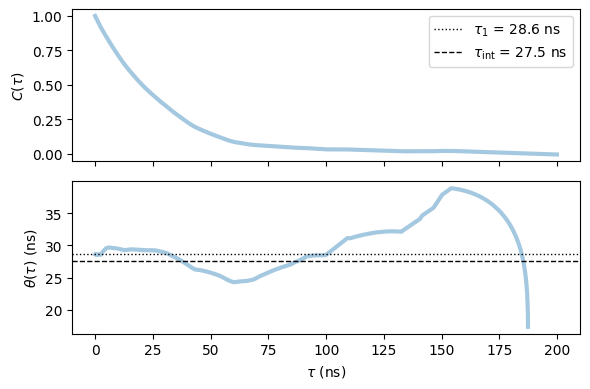

In [6]:
from src.dataclass import data_class
from src.acf import compute_acf_dataclass, compute_theta
from src.plots import plot_acf_theta


def compute_acf(signal, frametime, num_frames, c_window, calculate=True):
    if calculate:
        acf = compute_acf_dataclass(signal, frametime, num_frames, c_window=c_window)
    else:
        acf = None
    return data_class(sd.working_dir, "acf", acf)


num_frames_acf = 2000  # 400_000
c_window = 5
frametime = p.frametime / unit.picoseconds
ns = np.arange(num_frames_acf) * p.frametime / unit.nanoseconds

acf = compute_acf(sd.cvs[:, 0], frametime, num_frames_acf, c_window, calculate=True)
theta = compute_theta(acf.ct, frametime)

plot_acf_theta(ns, acf, theta, sd.timescales[0] / 1000, num_frames_acf)

[warn] Sokal window never closed; using the full series (tau may be tail-contaminated). Use a longer trajectory or a smaller c_window.
tau_int (blocks) = 24.7 +/- 3.3 ns


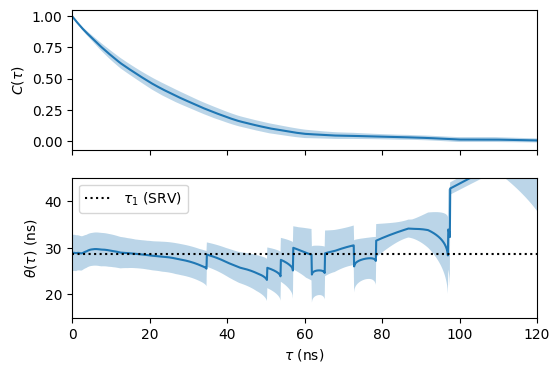

In [7]:
from src.acf import compute_acf_with_errors

res = compute_acf_with_errors(
    sd.cvs[:, 0], sd.frametime, 2000, num_blocks=8, c_window=5
)
t_ns = res["time"] / 1000

fig, axs = plt.subplots(2, 1, figsize=(6, 4), sharex=True)
axs[0].fill_between(
    t_ns, res["ct_mean"] - res["ct_err"], res["ct_mean"] + res["ct_err"], alpha=0.3
)
axs[0].plot(t_ns, res["ct_mean"])
axs[0].set_ylabel(r"$C(\tau)$")
axs[1].fill_between(
    t_ns,
    (res["theta_mean"] - res["theta_err"]) / 1000,
    (res["theta_mean"] + res["theta_err"]) / 1000,
    alpha=0.3,
)
axs[1].plot(t_ns, res["theta_mean"] / 1000)
axs[1].axhline(sd.timescales[0] / 1000, ls=":", color="k", label=r"$\tau_1$ (SRV)")
axs[1].set_xlim(0, 120)
axs[1].set_ylim(15, 45)
axs[1].set_xlabel(r"$\tau$ (ns)")
axs[1].set_ylabel(r"$\theta(\tau)$ (ns)")
axs[1].legend()
print(f"tau_int (blocks) = {res['tau_mean']/1000:.1f} +/- {res['tau_err']/1000:.1f} ns")

[warn] Sokal window never closed; using the full series (tau may be tail-contaminated). Use a longer trajectory or a smaller c_window.
theta reliable to 57 ns | tau_int = 24.7 +/- 3.3 ns


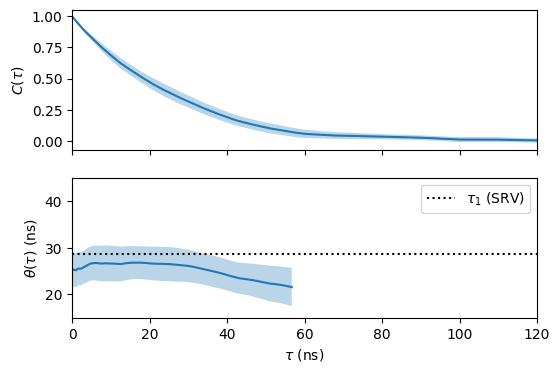

In [8]:
from src.acf import compute_acf_with_errors, compute_theta

res = compute_acf_with_errors(
    sd.cvs[:, 0], sd.frametime, 2000, num_blocks=8, c_window=5
)
theta, theta_err = compute_theta(res["ct_mean"], sd.frametime, ct_err=res["ct_err"])
ok = res["ct_mean"] > 2 * res["ct_err"]  # drop lags where C is lost in noise
t_ns = res["time"] / 1000

fig, axs = plt.subplots(2, 1, figsize=(6, 4), sharex=True)
axs[0].fill_between(
    t_ns, res["ct_mean"] - res["ct_err"], res["ct_mean"] + res["ct_err"], alpha=0.3
)
axs[0].plot(t_ns, res["ct_mean"])
axs[0].set_ylabel(r"$C(\tau)$")
axs[1].fill_between(
    t_ns[ok], (theta - theta_err)[ok] / 1000, (theta + theta_err)[ok] / 1000, alpha=0.3
)
axs[1].plot(t_ns[ok], theta[ok] / 1000)
axs[1].axhline(sd.timescales[0] / 1000, ls=":", color="k", label=r"$\tau_1$ (SRV)")
axs[1].set_xlim(0, 120)
axs[1].set_ylim(15, 45)
axs[1].set_xlabel(r"$\tau$ (ns)")
axs[1].set_ylabel(r"$\theta(\tau)$ (ns)")
axs[1].legend()
print(
    f"theta reliable to {t_ns[ok][-1]:.0f} ns | tau_int = {res['tau_mean']/1000:.1f} +/- {res['tau_err']/1000:.1f} ns"
)

In [3]:
import numpy as np


def cu(tau):
    return 0.8 * np.exp(-tau / 30) + 0.2 * np.exp(-tau / 1)


def thetau(tau):
    return -tau / np.log(cu(tau))


taus = [0.1, 1, 10, 100, 1000]

for tau in taus:
    print(f"{tau=:.1f}, theta={thetau(tau):.1f}")

tau=0.1, theta=4.6
tau=1.0, theta=6.0
tau=10.0, theta=18.0
tau=100.0, theta=28.1
tau=1000.0, theta=29.8


In [5]:
np.exp(1 / 1440)

np.float64(1.0006946856268137)

In [ ]:
taus = np.linspace(0, 2000, 200)
lambda1 = 1440  # ps
x = np.exp(1 / lambda1)

term1 = 0.7 * x**-taus
term2 = 0.1 * x**-taus

In [7]:
term1.shape

(200,)